# Modelagem probabilística e teoria de filas (RedesFilasAVMAula.ipynb)

- **Repositório:** `analise-de-dados-fundamentos`  
- **Tecnologias:** SciPy, NumPy  
- **Arquivo Original:** `RedesFilasAVMAula.ipynb`  

---


# Redes de filas

# Redes de filas fechadas
### Não compartilha subsistemas com outros sistemas

## Análise de valor médio

### Importar bibliotecas

In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

In [2]:
def AVM(Si, Vi, Nmax):
    if Si.shape != Vi.shape:
        raise('Ri e Vi devem ter mesma dimensão')
    Ni = np.zeros_like(Si)
    R = []
    MU = []
    N = range(1,Nmax+1)
    for n in N:
        Ri = Si * (1 + Ni)
        r = np.dot(Ri,Vi)
        R.append([r])
        mu = n / r
        MU.append([mu])
        Ni = mu * Ri * Vi
    return R, MU

### Exemplo 1
* Cada transação submetida ao servidor A realiza em média 10 solicitações (visitas) no servidor B e 5 solicitações (visitas) no servidor C  (16 visitas em A).
* Os tempos de serviço nos servidores A, B e C são respectivamente 125, 300 e 200 milissegundos.
* Realize a análise de valor médio para Nmax = 20.

In [3]:
# Dados do problema
Nmax = 20
# Tempo de serviço médio dos dispositivos
Si = np.array([0.125, 0.3, 0.2])
# Número de visitas nos dispositivos
Vi = np.array([16, 10, 5])

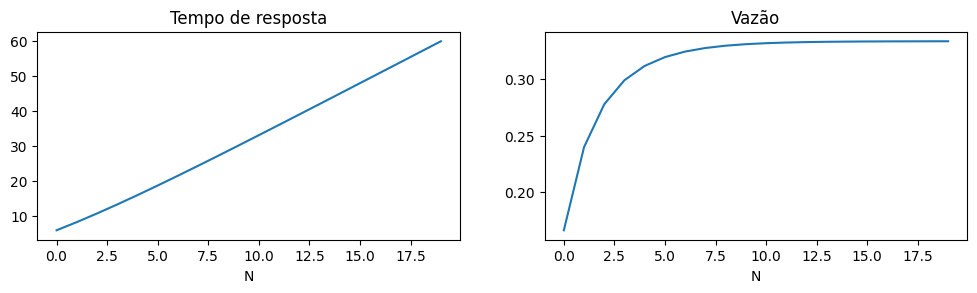

In [4]:
# iniciar array com número de tarefas no sistema
N = np.arange(Nmax)  # Número de tarefas no sistema

# Executar o algorimo AVM para calcular tempos de resposta e vazão
R, MU = AVM(Si, Vi, Nmax)

# Plotar gráficos
fig, ax = plt.subplots(1,2, figsize=(12, 2.7))  # Cria figura com dois subplots
ax[0].plot(N, R);
ax[0].set_title('Tempo de resposta')
ax[0].set_xlabel('N')
ax[1].plot(N, MU);
ax[1].set_title('Vazão');
ax[1].set_xlabel('N');

## Limites de desempenho
A utilização de um dispositivo é proporcional à sua demanda de serviço.<br>
O dispositivo com a maior demanda de serviço total (Di) é o dispositivo gargalo, considerado o fator limitante para se alcançar maiores taxas de vazão.<br>
A melhora de dispositivo gargalo tem um papel importante na melhora do desempenho do sistema (a melhora de outros dispositivos produz menor impacto).<br>
Identificação do gargalo é o primeiro passo em um projeto de melhoria de desempenho.<br>
Para determinar a demanda é necessário medir diretamente, ou medir o tempo médio de serviço e a quantidade de visitas (Di = Si ∙ Vi) <br>

### Teorema
Suponha que o dispositivo $G$ é o gargalo de um sistema.<br>
Isso significa que $D_{G}= D_{Max}$ é a maior entre todas as demandas $D_{1},D_{2},\cdots D_{M}$.<br><br>
A vazão e o tempo de resposta estão limitados de acordo com as seguintes equações:
* $\mu\le min\left\{  \frac{1}{D_{max}},\frac{N}{D} \right\}$


* $R\ge max\left\{ D,D\cdot D_{max} \right\}$

O número de tarefas no sistema é limitado de acordo com a seguinte expressão:
* $N^{*}=\frac{D}{D_{max}}$

### Exemplo 2
* Cada transação necessita de 5 segundos de CPU e faz 80 solicitações de E/S para o disco A e 100 solicitações de E/S para o disco B.
* O disco A leva 50ms para completar uma solicitação e o disco B leva 30ms.
* A vazão observada para o disco A foi de 15,7 solicitações de E/S por segundo.
* Determinar o número de tarefas no ponto de inflexão.

In [5]:
# Dados
Dcpu = 5
Va =80
Vb = 100
Sa = 0.05
Sb = 0.03
MuA = 1.57

# Cálculos
Vcpu = Va + Vb + 1
Da = Va*Sa
Db = Vb*Sb
Dmax = np.max([Dcpu, Da, Db])
print(Dmax)
D = np.sum([Dcpu, Da, Db])
print(D)
Nestrela = D/Dmax
print(Nestrela)

5.0
12.0
2.4


### Análise de limite de desempenho

In [6]:
def ALD(Di, Nmax):
    R = [[Di.sum(), Di.sum()]]
    MU = [[0, 0]]
    Nestrela = Di.sum()/Di.max()
    for N in range(1,Nmax+1):
        Rmin = max(N*Di.max(), Di.sum()+(N-1)*Di.mean())
        if N == 1:
            Rmax = Di.sum()
        else:
            Rmax = Di.sum()+(N-1)*Di.max()
        R.append([Rmin, Rmax])
        MUmin = N/Rmax
        MUmax = N/Rmin
        MU.append([MUmin, MUmax])
    return R, MU

### Exemplo 3
Analise os limites de desempenho para tarefas balanceadas, para a rede de filas do exemplo 2, para  Nmax = 8.
* $D_{A}= 2$
* $D_{B}= 3$
* $D_{A}= 1$

#### Executar o algoritmo ALD

In [7]:
# Vetor com demandas
Di = np.array([2, 3, 1], dtype=float)
# Di = np.array([1, 1, 1], dtype=float)

# Executar algoritmo ALD para calcular tempos de resposta e vazão
Nmax = 8
R, MU = ALD(Di, Nmax)

#### Plotar o gráfico de desempenho

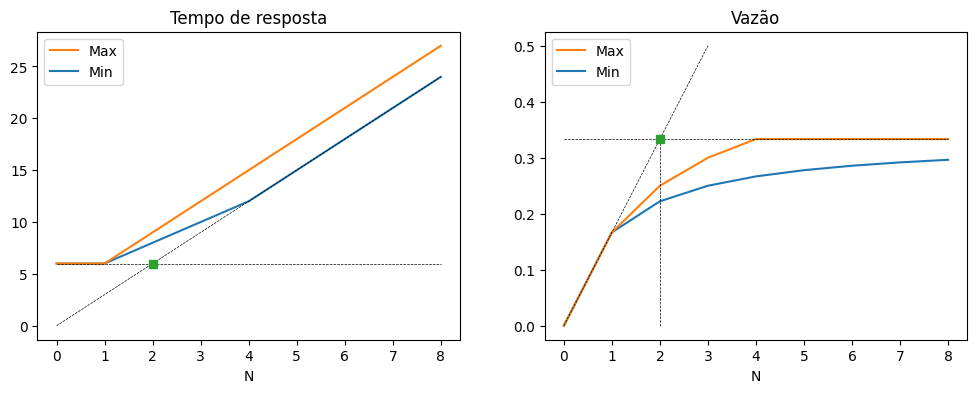

In [8]:
# Preparar dados para plotagem
Nestrela = Di.sum()/Di.max()
N = np.arange(0, Nmax+1)
N1 = np.arange(0, Nestrela+2)
N2 = np.ones_like(N)

# Criar figura com dois subplots
fig, ax = plt.subplots(1,2, figsize=(12, 4))

# Plotar gráfico de tempo de resposta
rMin, rMax = ax[0].plot(N, R);
ax[0].plot(N, N*Di.max(), color='black', linewidth=0.5, linestyle='--');
ax[0].plot(N, N2*Di.sum(), color='black', linewidth=0.5, linestyle='--');
ax[0].plot(Nestrela,Di.sum(), 's');
ax[0].set_title('Tempo de resposta')
ax[0].set_xlabel('N')
ax[0].legend([rMax, rMin], ["Max", "Min"], loc='upper left');

# Plotar gráfico de vazão
muMin, muMax = ax[1].plot(N, MU);
ax[1].plot(N1, N1 /(Di.sum()), color='black', linewidth=0.5, linestyle='--');
ax[1].plot(N, N2/Di.max(), color='black', linewidth=0.5, linestyle='--');
ax[1].vlines(Nestrela, 0, 1/Di.max(), color='black', linewidth=0.5, linestyle='--') ########
ax[1].plot(Nestrela,1/Di.max(), 's');
ax[1].set_title('Vazão');
ax[1].set_xlabel('N');
ax[1].legend([muMax, muMin], ["Max", "Min"], loc='upper left');
plt.plot;